# Logistic Regression

On the [What is Machine Learning?](00_what_is_machine_learning.qmd) page (section 7) you drew a straight line that separates spam from normal emails. In the [Classification](002_classification.ipynb) notebook you trained a random forest classifier, and in [Modeling & Evaluation](007_modeling_and_evaluation.ipynb) you evaluated classifiers with the confusion matrix, precision, recall, the F1 score and predicted probabilities.

In this notebook you will learn **logistic regression**, the simplest model for classification. Despite its name, it is a classification model: it predicts the probability that an input belongs to a class. It builds directly on the [Linear Regression](012_linear_regression.ipynb) notebook. A logistic regression model is a straight line whose output is turned into a probability, and it is trained with the same gradient descent loop.

We start with scikit-learn's `LogisticRegression` on one feature. Then we build the same model by hand, train it with gradient descent and check that we get the same result. After that we look at how the predicted probabilities become decisions.

### Outline

- `LogisticRegression` in scikit-learn
- From a line to a probability
- Learning the parameters
- Two features
- The threshold
- Precision-recall and ROC curves
- More than two classes
- Curved boundaries and regularization
- Exercise

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. `LogisticRegression` in scikit-learn

We go back to spam detection. To keep things simple, we start with a single feature: the number of links in an email. The label is 1 for spam and 0 for a normal email.

In [2]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(0) # fixed seed so that everyone gets the same data
n = 30 # number of emails per class

links_0 = np.random.poisson(2, n) # normal emails: few links
links_1 = np.random.poisson(6, n) # spam: more links

x = np.concatenate((links_0, links_1)).astype(float)
y = np.concatenate((np.zeros(n, dtype='int'), np.ones(n, dtype='int')))

x.shape, y.shape

((60,), (60,))

Let's plot the emails. The horizontal axis shows the number of links, the vertical axis the label. Many emails have the same number of links, so the points overlap. We make them transparent: darker points mean more emails.

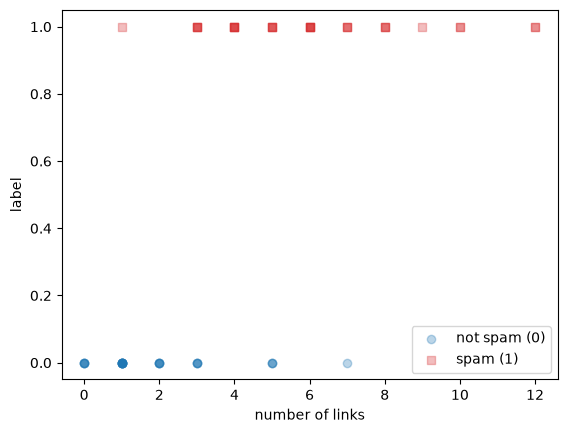

In [3]:
def plot_emails(x, y):
    plt.scatter(x[y==0], y[y==0], color='tab:blue', marker='o', alpha=0.3, label='not spam (0)')
    plt.scatter(x[y==1], y[y==1], color='tab:red', marker='s', alpha=0.3, label='spam (1)')
    plt.xlabel('number of links')
    plt.ylabel('label')

plt.figure(dpi=100)
plot_emails(x, y)
plt.legend()

Spam emails tend to have more links, but the classes overlap: some normal emails have 5 or 7 links, and some spam emails have only 1 or 3. No single number of links separates the two classes perfectly.

scikit-learn's `LogisticRegression` learns from these emails to predict the probability that an email is spam. Like `LinearRegression`, it expects `X` as a table with one column per feature, so we reshape `x` into a single column.

In [4]:
from sklearn.linear_model import LogisticRegression

X = x.reshape(-1, 1) # 60 rows, 1 column

model = LogisticRegression()
model.fit(X, y)
model.coef_, model.intercept_

(array([[0.84128064]]), array([-3.02297046]))

As in `LinearRegression`, `coef_` holds one weight per feature and `intercept_` holds the intercept. Section 2 shows how the model turns these two numbers into a probability.

A classifier in scikit-learn has two prediction methods. `predict_proba` returns the probability of each class, and `predict` returns the class. The first column of `predict_proba` is the probability of class 0 (not spam), the second the probability of class 1 (spam). Let's look at both for emails with 0, 3, 6 and 10 links.

In [5]:
new_emails = np.array([[0], [3], [6], [10]])

pd.DataFrame({
    'links': new_emails[:, 0],
    'probability of not spam': model.predict_proba(new_emails)[:, 0].round(3),
    'probability of spam': model.predict_proba(new_emails)[:, 1].round(3),
    'predict': model.predict(new_emails),
})

,links,probability of not spam,probability of spam,predict
0,0,0.954,0.046,0
1,3,0.622,0.378,0
2,6,0.117,0.883,1
3,10,0.005,0.995,1


The two probabilities in each row add up to 1. `predict` returns 1 exactly where the probability of spam is at least 0.5. This value is the **decision threshold**.

The plot shows the probability of spam for every number of links from 0 to 14.

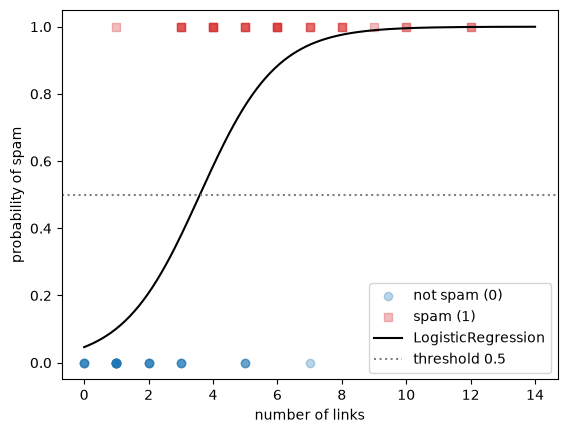

In [6]:
x_plot = np.linspace(0, 14, 200)

plt.figure(dpi=100)
plot_emails(x, y)
plt.plot(x_plot, model.predict_proba(x_plot.reshape(-1, 1))[:, 1], color='black', label='LogisticRegression')
plt.axhline(0.5, color='grey', ls=':', label='threshold 0.5')
plt.ylabel('probability of spam')
plt.legend()

The predicted probability is an S-shaped curve. It is close to 0 for emails with few links and close to 1 for emails with many links, and it never leaves the range from 0 to 1. It crosses the threshold of 0.5 between 3 and 4 links: from there on, the model predicts spam.

`score` returns the accuracy, as for the random forest in the [Classification](002_classification.ipynb) notebook.

In [7]:
model.score(X, y)

0.85

## 2. From a line to a probability

How does the model compute these probabilities from a weight and an intercept? It starts with a straight line.

You already know one model that predicts a number from a feature: linear regression. Let's fit a line to the labels and see what happens.

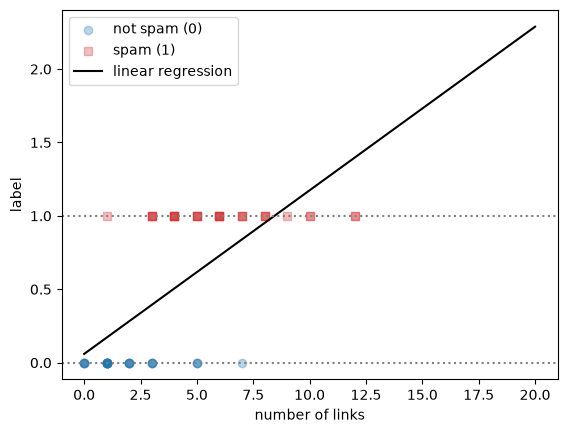

In [8]:
from sklearn.linear_model import LinearRegression

line = LinearRegression()
line.fit(X, y)

x_wide = np.linspace(0, 20, 200)

plt.figure(dpi=100)
plot_emails(x, y)
plt.plot(x_wide, line.predict(x_wide.reshape(-1, 1)), color='black', label='linear regression')
plt.axhline(0, color='grey', ls=':')
plt.axhline(1, color='grey', ls=':')
plt.legend()

In [9]:
line.predict([[0], [20]])

array([0.05981992, 2.28857983])

The line goes up with the number of links, which is the right trend. But we would like to read its output as the probability that an email is spam, and a probability must be between 0 and 1. For an email with 20 links, the line predicts 2.29, a probability of 229%. A straight line keeps going up forever, so it always leaves the range from 0 to 1 at some point. With other data, it can also go below 0 for small values.

We need a function that takes any number and squeezes it into the range from 0 to 1. The most common choice is the **sigmoid** function (also called the logistic function, which gives logistic regression its name):

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Text(0, 0.5, 'sigmoid(z)')

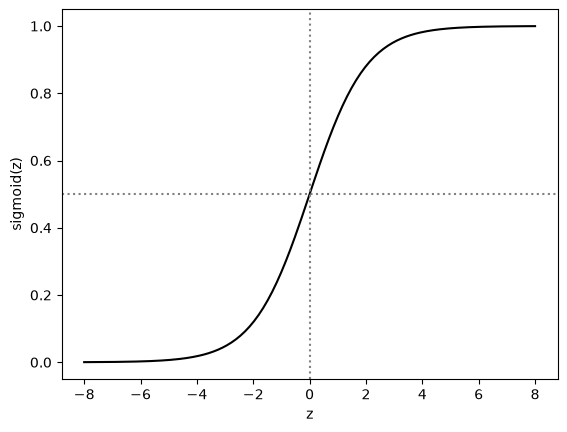

In [10]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)

plt.figure(dpi=100)
plt.plot(z, sigmoid(z), color='black')
plt.axhline(0.5, color='grey', ls=':')
plt.axvline(0, color='grey', ls=':')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')

In [11]:
for value in [-8, -2, 0, 2, 8]:
    print(f"sigmoid({value:2d}) = {sigmoid(value):.4f}")

sigmoid(-8) = 0.0003
sigmoid(-2) = 0.1192
sigmoid( 0) = 0.5000
sigmoid( 2) = 0.8808
sigmoid( 8) = 0.9997


The sigmoid has three properties that make it useful here:

* its output is always between 0 and 1;
* it is exactly 0.5 when $z = 0$;
* large negative values of $z$ give values close to 0, large positive values give values close to 1.

Take a moment to check these properties in the plot and in the printed values.

Logistic regression combines the two parts. First it computes a straight line, exactly like linear regression, then it passes the result through the sigmoid:

$$
p = \sigma(w \cdot x + b)
$$

Here $x$ is the number of links, $w$ is the weight (the slope, stored in `coef_`) and $b$ is the intercept (stored in `intercept_`). The output $p$ is the predicted probability that the email is spam.

Let's write this as a function and use it with the weight and intercept that scikit-learn found in section 1.

In [12]:
def predict_proba_by_hand(x, w, b):
    return sigmoid(w * x + b)

In [13]:
w = model.coef_[0, 0]
b = model.intercept_[0]

pd.DataFrame({
    'links': new_emails[:, 0],
    'p by hand': predict_proba_by_hand(new_emails[:, 0], w, b).round(3),
    'predict_proba': model.predict_proba(new_emails)[:, 1].round(3),
})

,links,p by hand,predict_proba
0,0,0.046,0.046
1,3,0.378,0.378
2,6,0.883,0.883
3,10,0.995,0.995


The probabilities are the same. A trained logistic regression model with one feature is just these two numbers and this formula.

The sigmoid is exactly 0.5 when its input is 0. So the model predicts spam ($p \geq 0.5$) when $w \cdot x + b \geq 0$, that is, when $x \geq -b / w$. This value of $x$ is the model's decision boundary.

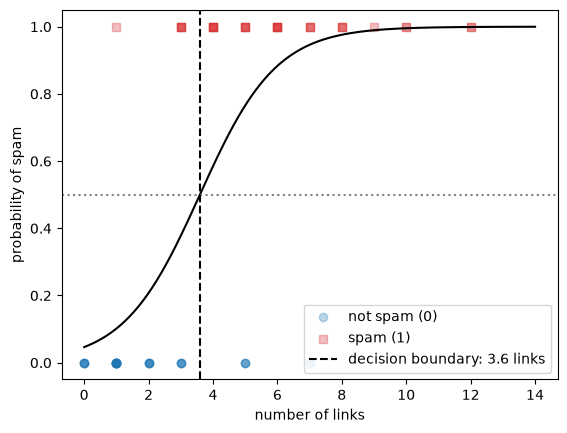

In [14]:
boundary = -b / w

plt.figure(dpi=100)
plot_emails(x, y)
plt.plot(x_plot, predict_proba_by_hand(x_plot, w, b), color='black')
plt.axhline(0.5, color='grey', ls=':')
plt.axvline(boundary, color='black', ls='--', label=f'decision boundary: {boundary:.1f} links')
plt.ylabel('probability of spam')
plt.legend()

In [15]:
y_pred = (predict_proba_by_hand(x, w, b) >= 0.5).astype(int) # 1 if the probability is at least 0.5, otherwise 0

print("same predictions as model.predict:", np.all(y_pred == model.predict(X)))
print(f"accuracy: {np.mean(y_pred == y):.3f}")

same predictions as model.predict: True
accuracy: 0.850


Every email to the right of the dashed line is predicted as spam, every email to the left as not spam. This is the same decision boundary as on the What is Machine Learning? page, but with one feature it is a point instead of a line.

The weight and the intercept decide the shape of the curve and where the boundary is. Let's try two other pairs of values.

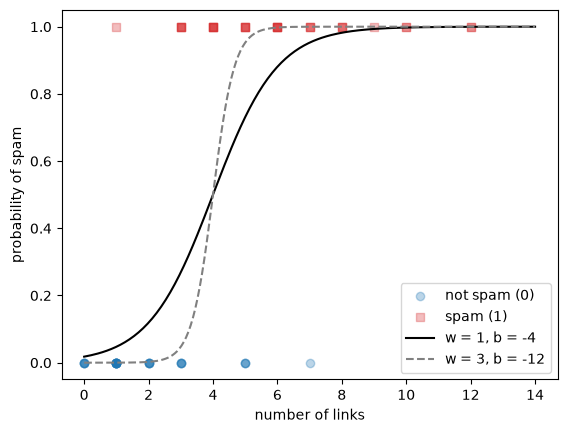

In [16]:
x_plot = np.linspace(0, 14, 200)

plt.figure(dpi=100)
plot_emails(x, y)
plt.plot(x_plot, predict_proba_by_hand(x_plot, w=1, b=-4), color='black', label='w = 1, b = -4')
plt.plot(x_plot, predict_proba_by_hand(x_plot, w=3, b=-12), color='grey', ls='--', label='w = 3, b = -12')
plt.ylabel('probability of spam')
plt.legend()

Both curves go from close to 0 (few links, probably not spam) to close to 1 (many links, probably spam). The weight $w$ controls how steep the curve is: with $w = 3$ the model switches from "not spam" to "spam" within a few links. Together, $w$ and $b$ decide where the switch happens: for both curves the boundary is at $-b / w = 4$ links.

Try a few other values for `w` and `b` in the cell above and see how the curve changes.

## 3. Learning the parameters

scikit-learn found $w$ and $b$ in section 1. In this section you find them yourself with gradient descent, as in the [Linear Regression](012_linear_regression.ipynb) notebook, and compare the result with `model.coef_` and `model.intercept_`.

In linear regression, the machine finds the parameters by making the cost as low as possible. We need a cost for logistic regression too.

The first idea is to use the accuracy. The cell below keeps $w = 1$ fixed and computes the accuracy for many values of $b$.

Text(0, 0.5, 'accuracy')

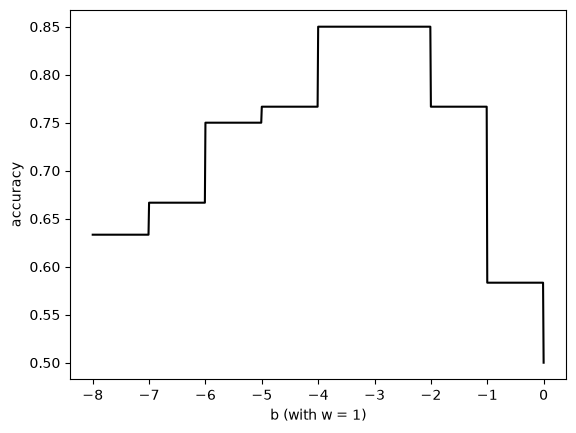

In [17]:
b_values = np.linspace(-8, 0, 801)
accuracies = [np.mean((predict_proba_by_hand(x, 1, b_value) >= 0.5) == y) for b_value in b_values]

plt.figure(dpi=100)
plt.plot(b_values, accuracies, color='black')
plt.xlabel('b (with w = 1)')
plt.ylabel('accuracy')

The accuracy changes in jumps. Between the jumps it is flat, because a small change in $b$ moves the boundary a little without changing any prediction. A flat stretch gives gradient descent no direction to move in, so the accuracy is not a useful cost for training.

Logistic regression uses the **log loss** instead (also called cross-entropy). For one email, the cost is:

* $-\log(p)$ if the email is spam ($y = 1$);
* $-\log(1 - p)$ if the email is not spam ($y = 0$).

Let's plot both.

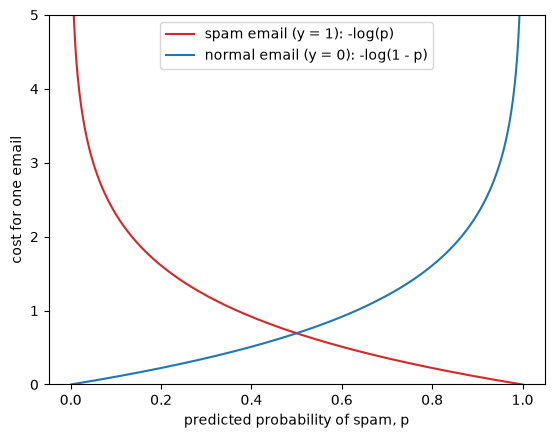

In [18]:
p_plot = np.linspace(0.001, 0.999, 500)

plt.figure(dpi=100)
plt.plot(p_plot, -np.log(p_plot), color='tab:red', label='spam email (y = 1): -log(p)')
plt.plot(p_plot, -np.log(1 - p_plot), color='tab:blue', label='normal email (y = 0): -log(1 - p)')
plt.xlabel('predicted probability of spam, p')
plt.ylabel('cost for one email')
plt.ylim(0, 5)
plt.legend()

For a spam email (red curve), the cost is 0 when the model predicts $p = 1$ and grows quickly as $p$ goes to 0. For a normal email (blue curve) it is the other way around. The log loss punishes confident wrong predictions much more than unsure ones. Let's compare two predictions for a normal email ($y = 0$):

In [19]:
print(f"normal email, unsure wrong prediction    p = 0.60: cost = {-np.log(1 - 0.60):.2f}")
print(f"normal email, confident wrong prediction p = 0.99: cost = {-np.log(1 - 0.99):.2f}")

normal email, unsure wrong prediction    p = 0.60: cost = 0.92
normal email, confident wrong prediction p = 0.99: cost = 4.61


Both predictions are wrong with a threshold of 0.5, so they count the same for the accuracy. The log loss is five times higher for the confident one.

The log loss of a model is the mean cost over all emails. The two cases can be written as one formula, because one of the two terms is always zero:

In [20]:
def log_loss_by_hand(y, p):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

log_loss_by_hand(y, predict_proba_by_hand(x, w=1, b=-4))

np.float64(0.39029105429348754)

Now we compare the log loss with the accuracy for the same values of $b$ as before.

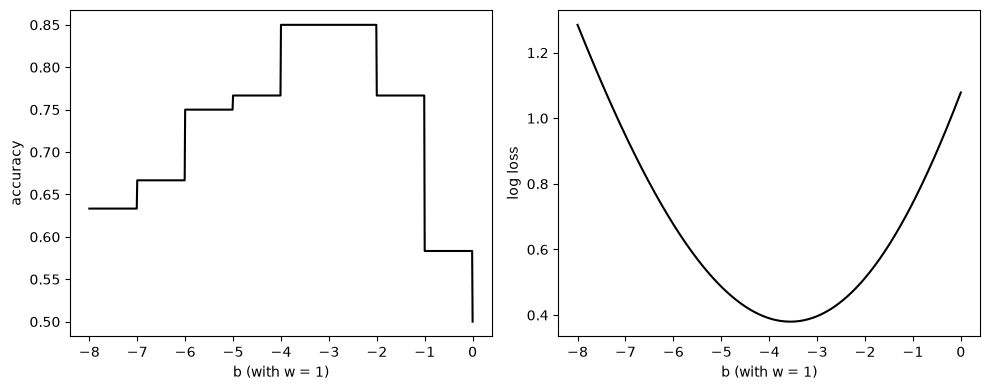

In [21]:
losses = [log_loss_by_hand(y, predict_proba_by_hand(x, 1, b_value)) for b_value in b_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
axes[0].plot(b_values, accuracies, color='black')
axes[0].set_xlabel('b (with w = 1)')
axes[0].set_ylabel('accuracy')
axes[1].plot(b_values, losses, color='black')
axes[1].set_xlabel('b (with w = 1)')
axes[1].set_ylabel('log loss')
plt.tight_layout()

The log loss is a smooth curve with a single lowest point, so gradient descent can follow it downhill. For logistic regression with the log loss, the slopes of the cost with respect to $w$ and $b$ are:

$$
\frac{\partial \text{cost}}{\partial w} = \text{mean}\big((p - y) \cdot x\big), \qquad
\frac{\partial \text{cost}}{\partial b} = \text{mean}(p - y)
$$

These have the same form as in the [Linear Regression](012_linear_regression.ipynb) notebook: the error times the feature, averaged over the data. The only difference is that the prediction is now the probability $p$. The loop below is the same gradient descent loop.

In [22]:
w, b = 0.0, 0.0       # start values
learning_rate = 0.1
n_steps = 3000

history = []
for step in range(n_steps + 1):
    p = predict_proba_by_hand(x, w, b)
    history.append((step, w, b, log_loss_by_hand(y, p)))

    # slopes of the log loss
    dw = np.mean((p - y) * x)
    db = np.mean(p - y)

    # take a step downhill
    w = w - learning_rate * dw
    b = b - learning_rate * db

history = pd.DataFrame(history, columns=['step', 'w', 'b', 'log loss'])
history.iloc[[0, 10, 100, 500, 1000, 2000, 3000]]

,step,w,b,log loss
0,0,0.000000,0.000000,0.693147
10,10,0.216197,-0.131950,0.576065
100,100,0.425170,-1.162009,0.449477
500,500,0.749815,-2.602938,0.381678
1000,1000,0.843055,-2.998842,0.377841
2000,2000,0.875527,-3.135621,0.377552
3000,3000,0.878446,-3.147890,0.377550


Text(0, 0.5, 'log loss')

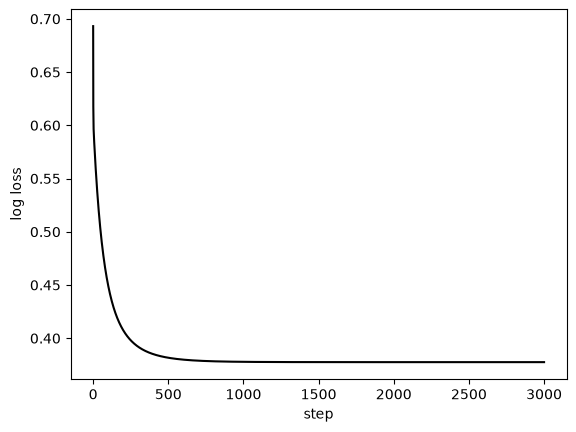

In [23]:
plt.figure(dpi=100)
plt.plot(history['step'], history['log loss'], color='black')
plt.xlabel('step')
plt.ylabel('log loss')

The log loss drops quickly in the first few hundred steps and then levels off. Let's see what the curve looks like at a few steps along the way.

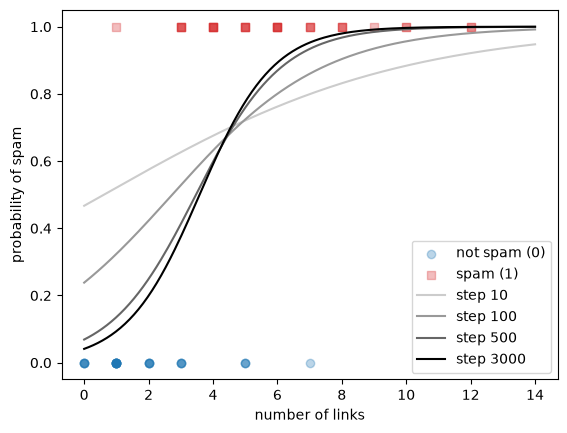

In [24]:
plt.figure(dpi=100)
plot_emails(x, y)
for step, color in zip([10, 100, 500, 3000], ['0.8', '0.6', '0.4', 'black']):
    row = history.iloc[step]
    plt.plot(x_plot, predict_proba_by_hand(x_plot, row['w'], row['b']), color=color, label=f'step {step}')
plt.ylabel('probability of spam')
plt.legend()

In [25]:
print(f"w = {w:.3f}, b = {b:.3f}")
print(f"decision boundary: {-b / w:.2f} links")
print(f"accuracy: {np.mean((predict_proba_by_hand(x, w, b) >= 0.5) == y):.3f}")

w = 0.878, b = -3.148
decision boundary: 3.58 links
accuracy: 0.850


The machine has found a weight, an intercept and a decision boundary on its own, by making the log loss as low as possible. Let's compare them with what scikit-learn found in section 1.

In [26]:
print(f"by hand:      w = {w:.3f}, b = {b:.3f}")
print(f"scikit-learn: w = {model.coef_[0, 0]:.3f}, b = {model.intercept_[0]:.3f}")

by hand:      w = 0.878, b = -3.148
scikit-learn: w = 0.841, b = -3.023


The values are close, but not the same. By default, `LogisticRegression` adds regularization, which keeps the weights a little smaller; you will meet it in section 8. Setting `C=np.inf` switches it off. scikit-learn uses a faster algorithm than our loop, but it minimizes the same log loss, so without regularization the results should match.

In [27]:
model_no_reg = LogisticRegression(C=np.inf)
model_no_reg.fit(X, y)

print(f"by hand:                        w = {w:.3f}, b = {b:.3f}")
print(f"scikit-learn, no regularization: w = {model_no_reg.coef_[0, 0]:.3f}, b = {model_no_reg.intercept_[0]:.3f}")

by hand:                        w = 0.878, b = -3.148
scikit-learn, no regularization: w = 0.879, b = -3.149


Both match our gradient descent result to two decimals.

## 4. Two features

With two features the model computes $w_1 \cdot x_1 + w_2 \cdot x_2 + b$ before the sigmoid. We go back to the emails from the What is Machine Learning? page: $x_1$ is the length of an email in hundreds of words and $x_2$ is the number of links. The data below was made so that short emails with many links are likely to be spam.

In [28]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(1)
m = 150 # number of emails

length = np.random.uniform(0.5, 9, m) # x1: length in hundreds of words
links = np.random.randint(0, 11, m).astype(float) # x2: number of links
z = 1.5 * (links - 0.9 * length - 1.2) # spam is likely when there are many links for the length
y2 = (np.random.rand(m) < sigmoid(z)).astype(int)

X2 = np.column_stack((length, links))
X2.shape, y2.mean().round(2)

((150, 2), np.float64(0.45))

In [29]:
from sklearn.model_selection import train_test_split

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=0, stratify=y2)

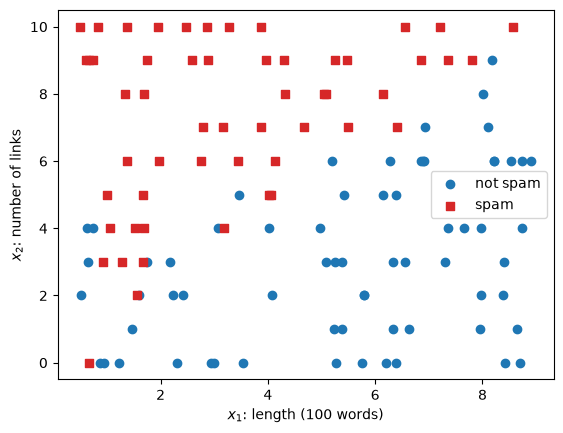

In [30]:
def plot_spam(X, y):
    plt.scatter(X[y==0, 0], X[y==0, 1], color='tab:blue', marker='o', label='not spam')
    plt.scatter(X[y==1, 0], X[y==1, 1], color='tab:red', marker='s', label='spam')
    plt.xlabel('$x_1$: length (100 words)')
    plt.ylabel('$x_2$: number of links')

plt.figure(dpi=100)
plot_spam(X2_train, y2_train)
plt.legend()

In [31]:
model2 = LogisticRegression()
model2.fit(X2_train, y2_train)

w1, w2 = model2.coef_[0]
b2 = model2.intercept_[0]
print(f"w1 = {w1:.3f}, w2 = {w2:.3f}, b = {b2:.3f}")

w1 = -1.040, w2 = 1.236, b = -2.146


The decision boundary is where $w_1 \cdot x_1 + w_2 \cdot x_2 + b = 0$. Solving for $x_2$ gives a straight line:

$$
x_2 = -\frac{w_1 \cdot x_1 + b}{w_2}
$$

The plot below shows this line, with the predicted probability of spam as background shading.

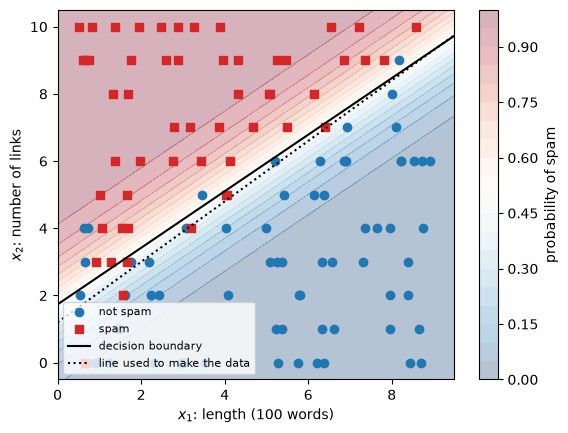

In [32]:
x1_grid, x2_grid = np.meshgrid(np.linspace(0, 9.5, 200), np.linspace(-0.5, 10.5, 200))
grid = np.column_stack((x1_grid.ravel(), x2_grid.ravel()))
proba_grid = model2.predict_proba(grid)[:, 1].reshape(x1_grid.shape)

x1_line = np.linspace(0, 9.5, 2)

plt.figure(dpi=100)
plt.contourf(x1_grid, x2_grid, proba_grid, levels=20, cmap='RdBu_r', alpha=0.3)
plt.colorbar(label='probability of spam')
plot_spam(X2_train, y2_train)
plt.plot(x1_line, -(w1 * x1_line + b2) / w2, color='black', label='decision boundary')
plt.plot(x1_line, 0.9 * x1_line + 1.2, color='black', ls=':', label='line used to make the data')
plt.ylim(-0.5, 10.5)
plt.legend(fontsize=8)

The model has found a line close to the one we used to make the data. Far from the line, the shading is dark: the model is confident. Close to the line, the probability is near 0.5 and the classes overlap.

Let's check the predictions on the test emails.

In [33]:
proba_test = model2.predict_proba(X2_test)[:, 1]

print("predict equals (probability >= 0.5):", np.all(model2.predict(X2_test) == (proba_test >= 0.5)))
print(f"test accuracy: {model2.score(X2_test, y2_test):.3f}")

predict equals (probability >= 0.5): True
test accuracy: 0.967


## 5. The threshold

So far we used 0.5 as the decision threshold. That is a choice, not something the model learns. In many problems the two kinds of mistakes do not cost the same, and another threshold is better.

We use the breast cancer dataset from [Modeling & Evaluation](007_modeling_and_evaluation.ipynb), with malignant = 1 as the positive class. Missing a malignant tumor (a false negative) is much worse than sending a healthy patient for an extra test (a false positive).

We need three sets: a training set to fit the model, a validation set to choose the threshold, and a test set for the final check. Choosing the threshold on the test set would make the test score too optimistic, for the same reason as tuning hyperparameters on it (007, section 2).

In [34]:
from sklearn.datasets import load_breast_cancer

X, y = load_breast_cancer(as_frame=True, return_X_y=True)
y = 1 - y # flip the labels: malignant = 1 (positive class), benign = 0

# 60% train, 20% validation, 20% test, with the same class ratios in each
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=3, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=3, stratify=y_train_full)

X_train.shape, X_val.shape, X_test.shape

((341, 30), (114, 30), (114, 30))

The features of this dataset have very different scales: some are below 1, others in the thousands. Logistic regression works best when the features are scaled, so we scale them as in [Data Preparation](005_data_prep.ipynb). The scaler is fitted on the training set only. Section 8 shows what happens without scaling.

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

cancer_model = LogisticRegression()
cancer_model.fit(X_train_s, y_train)

p_val = cancer_model.predict_proba(X_val_s)[:, 1] # probability of malignant

Before choosing a threshold, let's look at the predicted probabilities on the validation set, split by the true class.

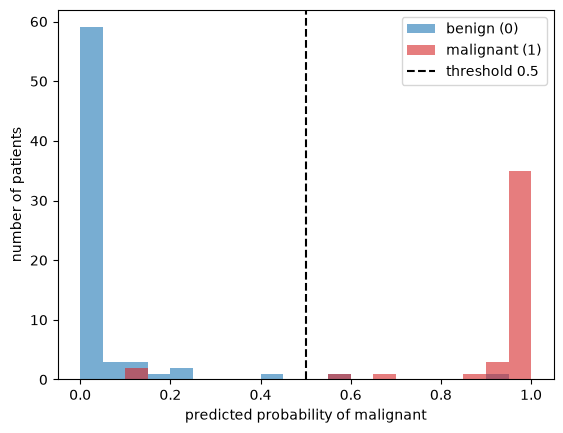

In [36]:
bins = np.linspace(0, 1, 21)

plt.figure(dpi=100)
plt.hist(p_val[y_val==0], bins=bins, color='tab:blue', alpha=0.6, label='benign (0)')
plt.hist(p_val[y_val==1], bins=bins, color='tab:red', alpha=0.6, label='malignant (1)')
plt.axvline(0.5, color='black', ls='--', label='threshold 0.5')
plt.xlabel('predicted probability of malignant')
plt.ylabel('number of patients')
plt.legend()

Most patients get a probability close to 0 or close to 1. The few in between are where the threshold matters. Moving the threshold to the left catches more malignant tumors, but also labels more benign tumors as malignant. Let's see this in the confusion matrix for three thresholds.

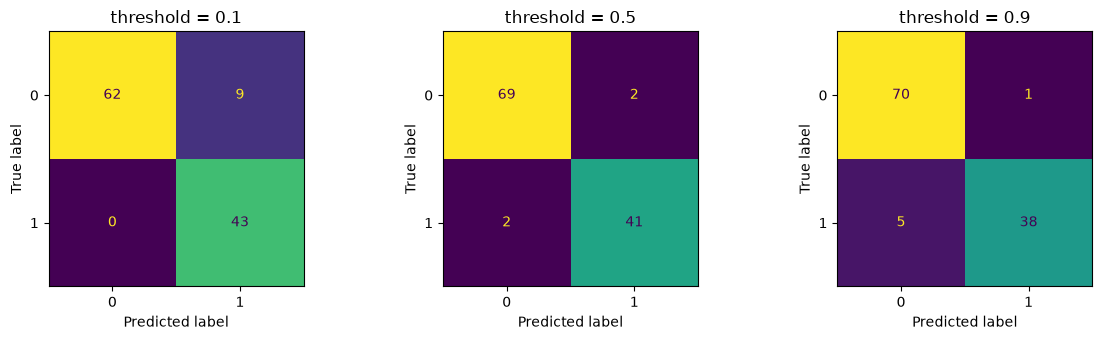

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), dpi=100)
for ax, threshold in zip(axes, [0.1, 0.5, 0.9]):
    y_pred = (p_val >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, ax=ax, colorbar=False)
    ax.set_title(f'threshold = {threshold}')
plt.tight_layout()

With a low threshold, the model misses fewer malignant tumors (bottom-left cell, false negatives) but raises more false alarms (top-right cell, false positives). With a high threshold it is the other way around.

Precision and recall measure exactly these two sides. We compute them by hand for many thresholds:

* precision = TP / (TP + FP): of the patients predicted malignant, the share that is malignant;
* recall = TP / (TP + FN): of the malignant patients, the share the model finds.

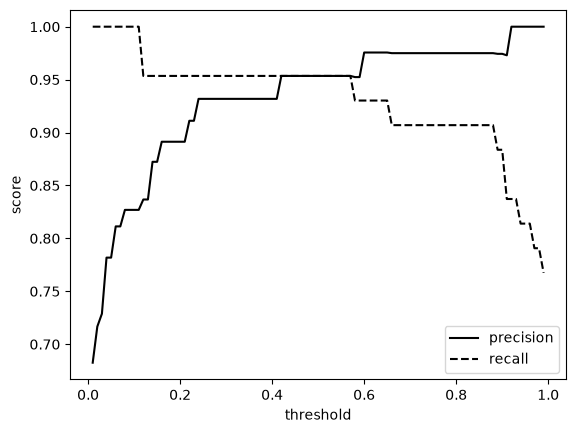

In [38]:
thresholds = np.linspace(0.01, 0.99, 99)
precisions, recalls = [], []

for threshold in thresholds:
    y_pred = (p_val >= threshold).astype(int)
    tp = np.sum((y_pred == 1) & (y_val == 1))
    fp = np.sum((y_pred == 1) & (y_val == 0))
    fn = np.sum((y_pred == 0) & (y_val == 1))
    precisions.append(tp / (tp + fp))
    recalls.append(tp / (tp + fn))

precisions, recalls = np.array(precisions), np.array(recalls)

plt.figure(dpi=100)
plt.plot(thresholds, precisions, color='black', label='precision')
plt.plot(thresholds, recalls, color='black', ls='--', label='recall')
plt.xlabel('threshold')
plt.ylabel('score')
plt.legend()

Raising the threshold increases the precision and lowers the recall. There is no threshold that maximizes both: this is the precision-recall trade-off. Which threshold is best depends on the cost of each mistake, which is a question about the problem, not about the model.

For the cancer data, we decide that the model must find at least 97% of the malignant tumors. We take the highest threshold that still gives this recall on the validation set, because a higher threshold gives fewer false alarms.

In [39]:
chosen = thresholds[recalls >= 0.97].max()
print(f"chosen threshold: {chosen:.2f}")
print(f"validation recall: {recalls[thresholds == chosen][0]:.3f}, precision: {precisions[thresholds == chosen][0]:.3f}")

chosen threshold: 0.11
validation recall: 1.000, precision: 0.827


Now the final check on the test set, which we have not used so far. We compare the default threshold with the chosen one.

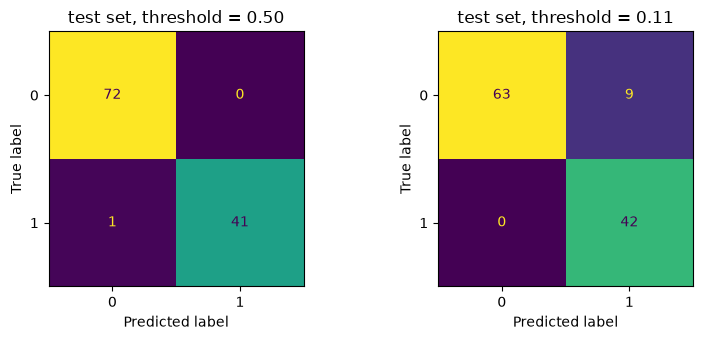

In [40]:
p_test = cancer_model.predict_proba(X_test_s)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=100)
for ax, threshold in zip(axes, [0.5, chosen]):
    ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= threshold).astype(int), ax=ax, colorbar=False)
    ax.set_title(f'test set, threshold = {threshold:.2f}')
plt.tight_layout()

Compare the bottom-left cells (false negatives) and the top-right cells (false positives). With the threshold of 0.5, the model misses one malignant tumor. With the chosen threshold it finds all of them, and in exchange it sends more healthy patients for an extra test. Which threshold to use depends on how much each kind of mistake costs, and that is decided by the people who use the model.

Take a moment to reflect: in which situations would you choose a threshold above 0.5 instead?

## 6. Precision-recall and ROC curves

Each threshold in section 5 gave one pair of precision and recall. If we plot these pairs against each other, we get the **precision-recall curve**. scikit-learn computes the same curve with `precision_recall_curve`, using every distinct predicted probability as a threshold. Let's plot both.

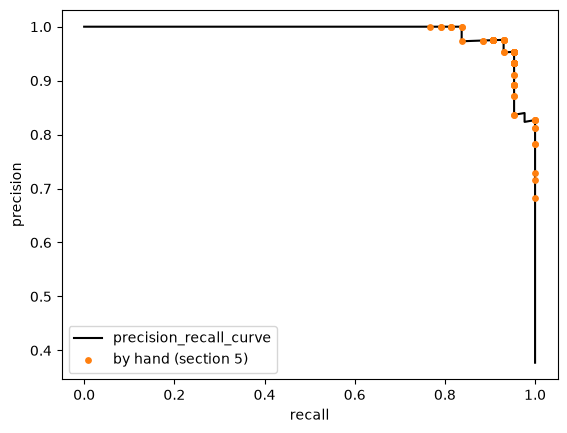

In [41]:
from sklearn.metrics import precision_recall_curve

precision_skl, recall_skl, _ = precision_recall_curve(y_val, p_val)

plt.figure(dpi=100)
plt.plot(recall_skl, precision_skl, color='black', label='precision_recall_curve')
plt.scatter(recalls, precisions, color='tab:orange', s=15, zorder=3, label='by hand (section 5)')
plt.xlabel('recall')
plt.ylabel('precision')
plt.legend()

Our points lie on scikit-learn's curve. The curve shows the whole trade-off at once: a good model keeps a high precision until the recall is close to 1.

A second common curve is the **ROC curve** (receiver operating characteristic). It plots, for every threshold:

* the true positive rate = TP / (TP + FN), which is the recall;
* the false positive rate = FP / (FP + TN): of the benign patients, the share predicted malignant.

We compute the false positive rate by hand, using the thresholds that scikit-learn's `roc_curve` returns, and check that we get the same rates.

In [42]:
from sklearn.metrics import roc_curve

fpr_skl, tpr_skl, roc_thresholds = roc_curve(y_val, p_val)

fpr_hand, tpr_hand = [], []
for threshold in roc_thresholds:
    y_pred = (p_val >= threshold).astype(int)
    tp = np.sum((y_pred == 1) & (y_val == 1))
    fp = np.sum((y_pred == 1) & (y_val == 0))
    fn = np.sum((y_pred == 0) & (y_val == 1))
    tn = np.sum((y_pred == 0) & (y_val == 0))
    tpr_hand.append(tp / (tp + fn))
    fpr_hand.append(fp / (fp + tn))

print("same true positive rates: ", np.allclose(tpr_hand, tpr_skl))
print("same false positive rates:", np.allclose(fpr_hand, fpr_skl))

same true positive rates:  True
same false positive rates: True


To see what a ROC curve says about a model, we compare our model with a weaker one that uses a single feature, `mean texture`.

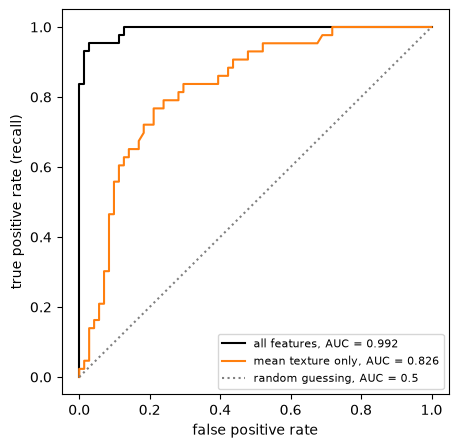

In [43]:
from sklearn.metrics import roc_auc_score

texture_model = LogisticRegression()
texture_model.fit(X_train_s[:, [list(X.columns).index('mean texture')]], y_train)
p_val_texture = texture_model.predict_proba(X_val_s[:, [list(X.columns).index('mean texture')]])[:, 1]
fpr_texture, tpr_texture, _ = roc_curve(y_val, p_val_texture)

plt.figure(dpi=100, figsize=(5, 5))
plt.plot(fpr_skl, tpr_skl, color='black', label=f'all features, AUC = {roc_auc_score(y_val, p_val):.3f}')
plt.plot(fpr_texture, tpr_texture, color='tab:orange', label=f'mean texture only, AUC = {roc_auc_score(y_val, p_val_texture):.3f}')
plt.plot([0, 1], [0, 1], color='grey', ls=':', label='random guessing, AUC = 0.5')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate (recall)')
plt.legend(fontsize=8)

A perfect model finds all malignant tumors without any false alarm, so its curve goes straight up to the top-left corner. A model that guesses at random follows the diagonal. The closer a curve gets to the top-left corner, the better the model separates the two classes.

The area under the ROC curve, the **AUC**, summarizes the curve in one number: 1 for a perfect model, 0.5 for random guessing. The AUC does not depend on a threshold, which makes it useful for comparing models before you choose one. The precision-recall curve has a similar summary, `average_precision_score`.

When the positive class is rare, the precision-recall curve is often more informative than the ROC curve. The false positive rate divides by the large number of negatives, so many false alarms still give a small false positive rate, while the precision drops.

## 7. More than two classes

Many problems have more than two classes, for example the four vehicle types in the [Classification](002_classification.ipynb) notebook. Logistic regression handles this by computing one straight-line score per class:

$$
s_k = w_{k,1} \cdot x_1 + w_{k,2} \cdot x_2 + b_k
$$

The **softmax** function then turns the scores into probabilities that add up to 1. It replaces the sigmoid, which only works for two classes:

$$
p_k = \frac{e^{s_k}}{\sum_j e^{s_j}}
$$

We start with made-up data with two features and three classes.

In [44]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(2)
n = 60 # points per class
centers = np.array([[1, 1], [4, 1.5], [2.5, 4]])

X3 = np.concatenate([np.random.randn(n, 2) * 0.9 + center for center in centers])
y3 = np.repeat([0, 1, 2], n)

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.3, random_state=0, stratify=y3)

In [45]:
model3 = LogisticRegression()
model3.fit(X3_train, y3_train)

print("coef_ has one row per class:", model3.coef_.shape)
print("intercept_ has one value per class:", model3.intercept_.shape)

coef_ has one row per class: (3, 2)
intercept_ has one value per class: (3,)


Let's compute the probabilities by hand for the first three test points and compare them with `predict_proba`.

In [46]:
scores = X3_test[:3] @ model3.coef_.T + model3.intercept_ # one score per class
proba_hand = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True) # softmax

print("by hand:\n", proba_hand.round(3))
print("predict_proba:\n", model3.predict_proba(X3_test[:3]).round(3))
print("rows add up to:", proba_hand.sum(axis=1))

by hand:
 [[0.282 0.691 0.026]
 [0.003 0.717 0.279]
 [0.993 0.007 0.   ]]
predict_proba:
 [[0.282 0.691 0.026]
 [0.003 0.717 0.279]
 [0.993 0.007 0.   ]]
rows add up to: [1. 1. 1.]


The model predicts the class with the highest probability. With three classes there is no single threshold to move: `np.argmax` picks the largest of the three probabilities in each row.

In [47]:
proba3 = model3.predict_proba(X3_test)
print("predict equals argmax of the probabilities:", np.all(model3.predict(X3_test) == np.argmax(proba3, axis=1)))

predict equals argmax of the probabilities: True


The plot below shows the prediction for every point of the plane. Each pair of classes is separated by a straight line, so the plane is split into three regions with straight edges.

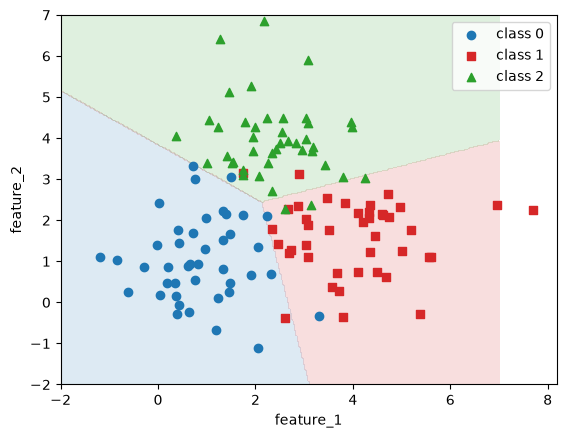

In [48]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-2, 7, 300), np.linspace(-2, 7, 300))
grid = np.column_stack((x1_grid.ravel(), x2_grid.ravel()))
regions = model3.predict(grid).reshape(x1_grid.shape)

colors = ['tab:blue', 'tab:red', 'tab:green']
markers = ['o', 's', '^']

plt.figure(dpi=100)
plt.contourf(x1_grid, x2_grid, regions, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.15)
for k in range(3):
    plt.scatter(X3_train[y3_train==k, 0], X3_train[y3_train==k, 1], color=colors[k], marker=markers[k], label=f'class {k}')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()

The evaluation tools from 007 work for three classes too. The confusion matrix gets one row and one column per class, and there is one F1 score per class.

F1 per class: [0.944 0.872 0.848]
macro-F1: 0.888


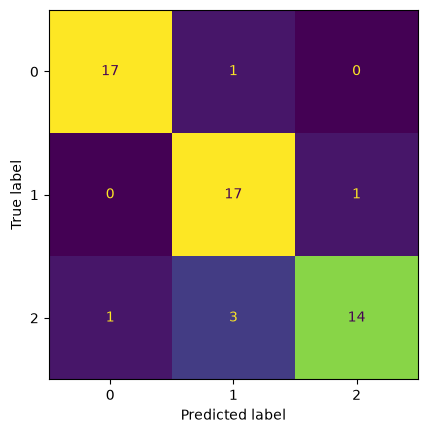

In [49]:
from sklearn.metrics import f1_score

y3_pred = model3.predict(X3_test)

plt.figure(dpi=100)
ConfusionMatrixDisplay.from_predictions(y3_test, y3_pred, ax=plt.gca(), colorbar=False)

print("F1 per class:", f1_score(y3_test, y3_pred, average=None).round(3))
print(f"macro-F1: {f1_score(y3_test, y3_pred, average='macro'):.3f}")

The macro-F1 is the plain mean of the per-class F1 scores, so every class counts equally (007, section 8).

## 8. Curved boundaries and regularization

Logistic regression draws a straight decision boundary. Many datasets need a curved one. The made-up dataset below has two classes shaped like two half moons. We train on only 80 points, which makes overfitting easier to see, and keep 320 points for testing so that the test accuracy is reliable.

In [50]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
from sklearn.datasets import make_moons
X4, y4 = make_moons(n_samples=400, noise=0.3, random_state=0)

# only 80 points for training, the other 320 for testing
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y4, test_size=0.8, random_state=0, stratify=y4)

We will draw several decision boundaries, so we write a small function. It takes a function that predicts classes, computes the predictions on a grid and shades the two regions.

In [51]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid4 = np.column_stack((x1_grid.ravel(), x2_grid.ravel()))

def plot_boundary(predict, X, y, ax):
    regions = predict(grid4).reshape(x1_grid.shape)
    ax.contourf(x1_grid, x2_grid, regions, levels=[-0.5, 0.5, 1.5], colors=['tab:blue', 'tab:red'], alpha=0.15)
    ax.scatter(X[y==0, 0], X[y==0, 1], color='tab:blue', marker='o', s=12)
    ax.scatter(X[y==1, 0], X[y==1, 1], color='tab:red', marker='s', s=12)
    ax.set_xlabel('feature_1')
    ax.set_ylabel('feature_2')

Text(0.5, 1.0, 'straight line: train accuracy 0.82, test accuracy 0.86')

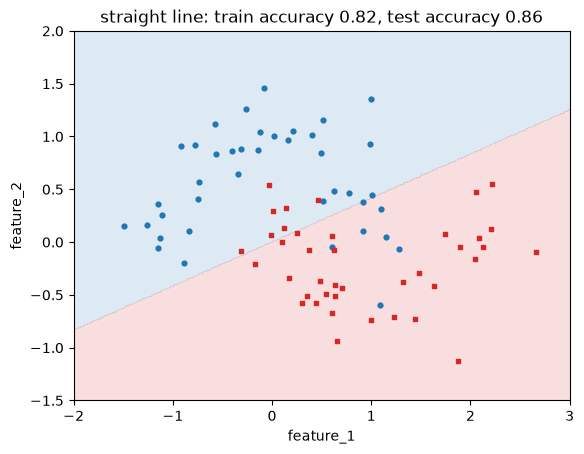

In [52]:
straight = LogisticRegression()
straight.fit(X4_train, y4_train)

plt.figure(dpi=100)
plot_boundary(straight.predict, X4_train, y4_train, plt.gca())
plt.title(f'straight line: train accuracy {straight.score(X4_train, y4_train):.2f}, test accuracy {straight.score(X4_test, y4_test):.2f}')

A straight line cannot follow the moons, so the model underfits. The fix is the same as in the [Linear Regression](012_linear_regression.ipynb) notebook: add polynomial features. `PolynomialFeatures` adds columns such as $x_1^2$, $x_1 \cdot x_2$ and $x_2^3$. The model is still a straight line in these new columns, but in the original two features the boundary is curved.

The new columns have very different scales, so we scale them after creating them. The transformers are fitted on the training set only, and the same fitted transformers are applied to the test set and to the grid.

columns after PolynomialFeatures: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2' 'x1^3' 'x1^2 x2' 'x1 x2^2' 'x2^3']


Text(0.5, 1.0, 'degree 3: train accuracy 0.89, test accuracy 0.88')

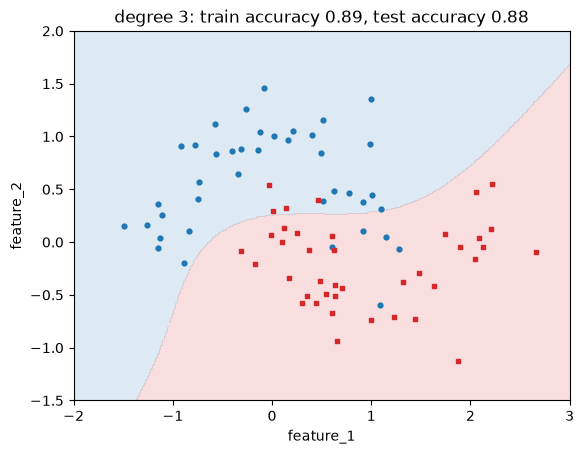

In [53]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=3, include_bias=False)
X4_train_poly = poly.fit_transform(X4_train)
print("columns after PolynomialFeatures:", poly.get_feature_names_out(['x1', 'x2']))

poly_scaler = StandardScaler()
X4_train_poly_s = poly_scaler.fit_transform(X4_train_poly)

curved = LogisticRegression()
curved.fit(X4_train_poly_s, y4_train)

def predict_curved(X):
    return curved.predict(poly_scaler.transform(poly.transform(X)))

X4_test_poly_s = poly_scaler.transform(poly.transform(X4_test))

plt.figure(dpi=100)
plot_boundary(predict_curved, X4_train, y4_train, plt.gca())
plt.title(f'degree 3: train accuracy {curved.score(X4_train_poly_s, y4_train):.2f}, test accuracy {curved.score(X4_test_poly_s, y4_test):.2f}')

The boundary now bends around the moons, and the test accuracy is higher.

### The `C` hyperparameter

With many polynomial features, the boundary can bend too much and follow the noise in the training data. As in linear regression, regularization keeps the weights small. In `LogisticRegression` the strength is set with `C`. `C` works in the opposite direction of `alpha` in `Ridge`: a small `C` means strong regularization, a large `C` means weak regularization. The default is `C=1`, so scikit-learn's logistic regression is always somewhat regularized unless you change it, which is why we used `C=np.inf` in section 3.

Let's use degree 8 and three values of `C`.

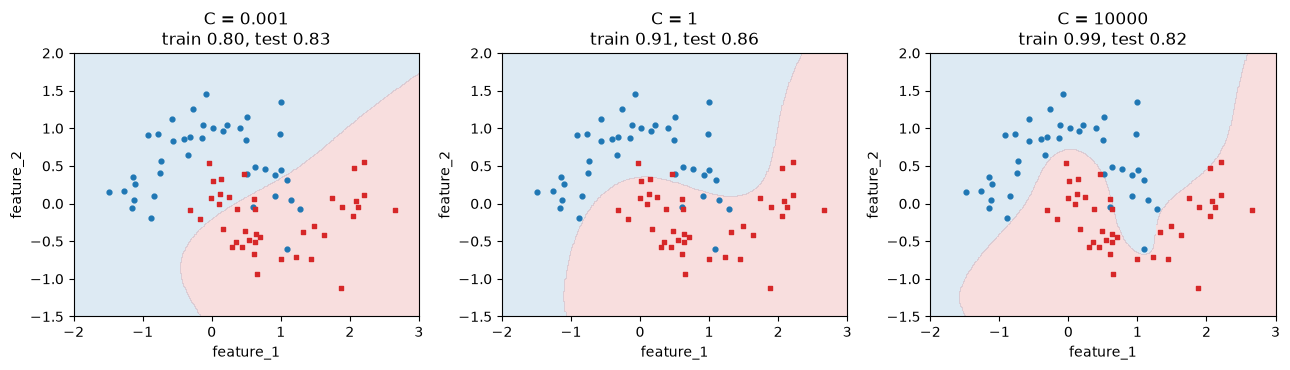

In [54]:
poly8 = PolynomialFeatures(degree=8, include_bias=False)
scaler8 = StandardScaler()
X4_train_8 = scaler8.fit_transform(poly8.fit_transform(X4_train))
X4_test_8 = scaler8.transform(poly8.transform(X4_test))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), dpi=100)
for ax, C in zip(axes, [0.001, 1, 10000]):
    model_C = LogisticRegression(C=C, max_iter=10000)
    model_C.fit(X4_train_8, y4_train)
    plot_boundary(lambda X: model_C.predict(scaler8.transform(poly8.transform(X))), X4_train, y4_train, ax)
    ax.set_title(f'C = {C}\ntrain {model_C.score(X4_train_8, y4_train):.2f}, test {model_C.score(X4_test_8, y4_test):.2f}')
plt.tight_layout()

With `C = 0.001` the regularization is so strong that the boundary is a gentle curve that cuts through both moons. The model underfits, and both accuracies are low. With `C = 10000` the boundary twists around single training points. The model overfits, with a training accuracy of 0.99 and a much lower test accuracy. `C = 1` is in between.

The plot below shows the accuracy for many values of `C`. The training accuracy keeps rising as `C` grows, while the test accuracy first rises and then falls. This is the same pattern as for the polynomial degree on the What is Machine Learning? page (section 6).

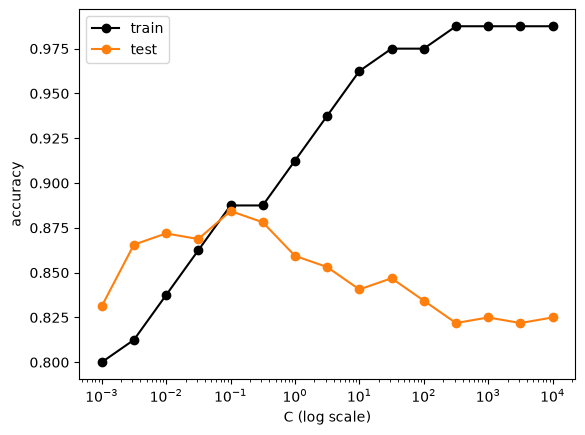

In [55]:
C_values = np.logspace(-3, 4, 15)
train_scores, test_scores = [], []
for C in C_values:
    model_C = LogisticRegression(C=C, max_iter=10000)
    model_C.fit(X4_train_8, y4_train)
    train_scores.append(model_C.score(X4_train_8, y4_train))
    test_scores.append(model_C.score(X4_test_8, y4_test))

plt.figure(dpi=100)
plt.plot(C_values, train_scores, color='black', marker='o', label='train')
plt.plot(C_values, test_scores, color='tab:orange', marker='o', label='test')
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('accuracy')
plt.legend()

In practice you choose `C` with cross-validation on the training data, as in 007, and not by looking at the test set as we did here for the plot.

### Why we scaled the features

In section 5 we scaled the breast cancer features before fitting. Let's see what happens without scaling. scikit-learn shows a `ConvergenceWarning`: the algorithm stopped after its maximum number of steps (`max_iter=100`) before it reached the lowest cost. We catch the warning and print only its first line, so that the message stays short.

In [56]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    unscaled = LogisticRegression()
    unscaled.fit(X_train, y_train) # not scaled

for warning in caught:
    print(f"{type(warning.message).__name__}: {str(warning.message).splitlines()[0]}")

print(f"validation accuracy without scaling: {unscaled.score(X_val, y_val):.3f}")
print(f"validation accuracy with scaling:    {cancer_model.score(X_val_s, y_val):.3f}")

validation accuracy without scaling: 0.956
validation accuracy with scaling:    0.965


A warning is not an error: the model was trained and makes predictions. But it has not finished training, and the result depends on how far it got. When one feature is in the thousands and another below 1, the cost surface is a long, narrow valley, and gradient-based algorithms need many small steps to get down it. After scaling, all features have a similar range and the algorithm converges in a few steps.

Increasing `max_iter` also removes the warning, but scaling is the better fix. It is also needed for regularization to treat all weights fairly, because the size of a weight depends on the scale of its feature.

## 9. Exercise

In the [Classification](002_classification.ipynb) notebook you trained a random forest on the vehicle dataset, which has four classes. Now compare it with logistic regression.

In [57]:
from sklearn.datasets import fetch_openml

X_vehicle, y_vehicle = fetch_openml(name="vehicle", version=1, as_frame=True, return_X_y=True)
y_vehicle.value_counts()

Class
bus     218
saab    217
opel    212
van     199
Name: count, dtype: int64

1. Split the data into a training set (80%) and a test set (20%) with `stratify` and `random_state=0`.

In [58]:
# YOUR CODE HERE

2. Scale the features with a `StandardScaler` fitted on the training set. Train a `LogisticRegression` and compute the macro-F1 on the test set. If you see a `ConvergenceWarning`, check that you used the scaled features.

In [59]:
# YOUR CODE HERE

3. Train a `RandomForestClassifier(random_state=0)` on the same split and compute its macro-F1. Which model is better on this dataset?

In [60]:
# YOUR CODE HERE

4. Plot the confusion matrix of the better model. Which classes does it confuse most often? Look at the class names and think about why.

In [61]:
# YOUR CODE HERE

5. Try `C` values from 0.01 to 100 for the logistic regression. Choose the best value with `cross_val_score(..., scoring='f1_macro')` on the training set, then check the test score of that value once.

In [62]:
# YOUR CODE HERE

## Further reading

These are optional, for a second explanation of the same ideas:

- Géron, *Hands-On Machine Learning*, chapter 3 (sections on the precision/recall trade-off and the ROC curve) and chapter 4 (section "Logistic Regression").
- James et al., [*An Introduction to Statistical Learning with Applications in Python*](https://www.statlearning.com/), chapter 4 (free to read online).